# Import Required Libraries
Import the necessary libraries, including cProfile and pstats.

In [1]:
# Import the necessary libraries for profiling and visualizing the results
import cProfile
import pstats

In [6]:
from anemone.experiment import *
from anemone.forwards import *
import torch

# Define the Function to Profile
Define the function or code block that you want to profile.

In [36]:
# Define the function to profile

tx = Loop.square(40)
rx = Receiver()
time = torch.logspace(-5, -3, 31)

rho = torch.ones(3)*40.
rho_change = torch.linspace(-30, 260, 100)
rho = rho[:, None] + rho_change[None, :]
rho[0, :] = 40.
rho[2, :] = 40.

thick = np.ones_like(rho)[:-1, :]*30

fwr = ForwardLaplace3(tx, rx, time, waveform=Waveform.example())
dbdt = fwr(rho, thick)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


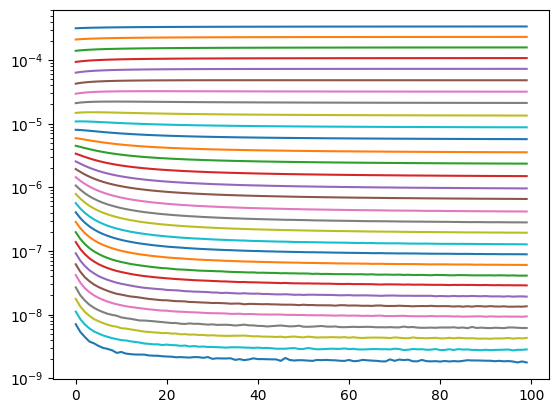

In [37]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.semilogy(dbdt);

In [38]:
%%timeit
dbdt = fwr(rho, thick)

393 ms ± 19.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [39]:
def example_function():
    dbdt = fwr(rho, thick)

# Use cProfile to Profile the Function
Use the cProfile.run() function to profile the defined function or code block.

In [40]:
# Use cProfile to Profile the Function
cProfile.run('example_function()', 'profile_output')

# Load the profiling results
profile_stats = pstats.Stats('profile_output')

# Sort the statistics by cumulative time and print the top 10 functions
profile_stats.sort_stats('cumulative').print_stats(10)

Thu Oct 31 14:24:30 2024    profile_output

         1231 function calls in 0.451 seconds

   Ordered by: cumulative time
   List reduced from 82 to 10 due to restriction <10>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.451    0.451 {built-in method builtins.exec}
        1    0.000    0.000    0.451    0.451 <string>:1(<module>)
        1    0.000    0.000    0.451    0.451 C:\Users\au646858\AppData\Local\Temp\ipykernel_11280\3089854814.py:1(example_function)
        1    0.001    0.001    0.451    0.451 c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\forwards\forwards.py:114(__call__)
        1    0.000    0.000    0.450    0.450 c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\forwards\forwards.py:710(forward)
        1    0.000    0.000    0.450    0.450 c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\sr

# Visualize Profiling Results with pstats
Use the pstats module to load and visualize the profiling results.

In [41]:
# Visualize Profiling Results with pstats

# Strip directories to shorten the output
profile_stats.strip_dirs()

# Sort the statistics by time spent within each function and print the top 10 functions
profile_stats.sort_stats('time').print_stats()

# Print the callers of the top 10 functions
profile_stats.print_callers()

Thu Oct 31 14:24:30 2024    profile_output

         1231 function calls in 0.451 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
       27    0.181    0.007    0.422    0.016 physics.py:112(refl_transverse_electric)
       54    0.153    0.003    0.153    0.003 {built-in method torch.sqrt}
       27    0.078    0.003    0.078    0.003 {built-in method torch.tanh}
       27    0.017    0.001    0.441    0.016 forwards.py:713(s_integrand)
        1    0.006    0.006    0.447    0.447 transforms.py:417(__call__)
       27    0.004    0.000    0.004    0.000 physics.py:21(calc_wavenumber)
       27    0.004    0.000    0.004    0.000 physics.py:12(calc_zy)
        1    0.001    0.001    0.450    0.450 transforms.py:268(_range)
       54    0.001    0.000    0.001    0.000 {built-in method torch.ones_like}
       28    0.001    0.000    0.001    0.000 _tensor.py:911(__rdiv__)
        8    0.001    0.000    0.001    0.000 {built